# Universal Silica Fiber FEM Lab — v0.1

**직접 단면을 설계하고 실행 결과를 보는 Google Colab 실험실**

**지원 범위:** 실리카 기반 **원형·축대칭·고체 코어** 광섬유의 Step-index, Graded-index, Trench-assisted, 임의 다층 굴절률 단면. 약유도 **LP₀₁ 스칼라 radial P1 FEM**을 계산합니다.

**미지원:** 실제 제조사 굴절률 프로파일 자동복원, Full-vector Maxwell/PML, 누설·흡수·굽힘 손실, PMD/복굴절, 비원형 PCF·MCF, 반공진 HCF/NANF, 임의 형상 3D. 해당 항목은 후속 버전에서 구현·검증해야 합니다.

**사용 방법:** `런타임 → 모두 실행`을 누르세요. **2. 입력 모델**에서 파장·코어 크기·트렌치 깊이·다층 재료 굴절률을 바꾼 뒤 재실행할 수 있습니다. 도핑 물성은 실리카 굴절률 + 일정한 Δn으로 근사했으므로 분산 결과는 가정에 민감합니다. 실측 제품 적합성 인증이 아닙니다.

## 1. 기본 설정 및 물리 엔진

Google Colab에는 보통 NumPy, SciPy, Matplotlib, Pandas가 설치되어 있습니다. 없는 환경에서만 별도 설치가 필요합니다: `%pip install numpy scipy matplotlib pandas ipywidgets`.

고유치 방정식은 축대칭 스칼라 모드에 대한 반경 FEM입니다. 코어/트렌치 재료 경계는 **메시 노드에 일치하도록 분할**하고, 각 요소에서 5점 Gauss 적분으로 굴절률을 적분합니다. 계산의 끝점은 0 전기장 Dirichlet 경계이며 실제 125 µm 클래딩 반경이 아닙니다.

In [1]:
"""Research prototype v0.1: rotationally symmetric solid-silica fibers.

Scalar weak-guidance radial P1 finite element mode solver for LP01.
Materials are silica baseline Sellmeier plus *constant* delta_n offsets;
this is an illustrative index model, not a verified Ge/F doped Sellmeier law.
This solver does NOT model HCF/NANF, noncircular MCF, birefringence, loss, bends,
or fiber manufacturing variation. All transverse dimensions are in micrometres.
"""
from __future__ import annotations
from dataclasses import dataclass, replace, asdict
from typing import Sequence
import json
import numpy as np
from scipy.special import j0,j1,k0 as K0,k1 as K1
from scipy.optimize import brentq
from scipy.integrate import quad
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import eigsh
from numpy.polynomial.legendre import leggauss

C0=299792458.0
_SELL_B=(0.6961663,0.4079426,0.8974794)
_SELL_C=(0.0684043**2,0.1162414**2,9.896161**2)

@dataclass(frozen=True)
class Model:
    profile: str = 'step'                  # step, graded, trench, multilayer
    wavelength_nm: float = 1550.0
    core_radius_um: float = 5.5
    delta_n_core: float = 0.0034785793846155
    outer_radius_um: float = 40.0       # computational, not physical cladding radius
    graded_alpha: float = 2.0
    trench_start_um: float = 7.0
    trench_end_um: float = 10.0
    trench_delta_n: float = -0.001
    # custom shells are (outer_radius_um, absolute delta_n relative to silica baseline).
    # First one starts at r=0; last listed shell may end before outer_radius_um.
    shells: tuple[tuple[float,float],...] = ((5.0,0.004), (7.0,0.0), (9.0,-0.0007))
    n2_m2_per_W: float = 2.2e-20
    def validate(self):
        if self.profile not in ('step','graded','trench','multilayer'):
            raise ValueError('profile must be step, graded, trench, or multilayer')
        for name in ('wavelength_nm','core_radius_um','outer_radius_um','graded_alpha','n2_m2_per_W'):
            x=float(getattr(self,name))
            if not np.isfinite(x) or x<=0: raise ValueError(f'{name} must be positive/finite')
        if not 250 < self.wavelength_nm < 3600: raise ValueError('wavelength outside silica Sellmeier domain')
        if self.outer_radius_um<=2.2*self.core_radius_um: raise ValueError('outer radius must exceed 2.2 x core radius')
        for name in ('delta_n_core','trench_delta_n'):
            if not np.isfinite(getattr(self,name)): raise ValueError(name)
        if self.profile=='trench' and not (self.core_radius_um < self.trench_start_um < self.trench_end_um < self.outer_radius_um):
            raise ValueError('trench radii must be core < start < end < outer')
        if self.profile=='multilayer':
            if not self.shells: raise ValueError('shells required')
            rr=np.array([x[0] for x in self.shells]); nn=np.array([x[1] for x in self.shells]);
            if np.any(~np.isfinite(rr)) or np.any(~np.isfinite(nn)) or np.any(np.diff(rr)<=0) or rr[0]<=0 or rr[-1]>=self.outer_radius_um:
                raise ValueError('shell boundaries must increase and lie below outer radius')
        return self

def silica_index(wavelength_um):
    w=np.asarray(wavelength_um,dtype=float)
    if np.any((w<=0.21)|(w>=3.7)): raise ValueError('silica Sellmeier only 0.21–3.7 µm')
    return np.sqrt(1+sum(b*w*w/(w*w-c) for b,c in zip(_SELL_B,_SELL_C)))

def boundaries(m:Model):
    m.validate()
    if m.profile=='trench': marks=[m.core_radius_um,m.trench_start_um,m.trench_end_um]
    elif m.profile=='multilayer': marks=[r for r,d in m.shells]
    else: marks=[m.core_radius_um]
    return np.r_[0.0,marks,m.outer_radius_um]

def delta_n_r(m:Model,r):
    r=np.asarray(r,dtype=float)
    if m.profile=='step': return np.where(r<m.core_radius_um,m.delta_n_core,0.0)
    if m.profile=='graded': return np.where(r<m.core_radius_um,m.delta_n_core*np.maximum(1-(r/m.core_radius_um)**m.graded_alpha,0),0.0)
    if m.profile=='trench':
        return np.where(r<m.core_radius_um,m.delta_n_core,
                        np.where((r>=m.trench_start_um)&(r<m.trench_end_um),m.trench_delta_n,0.0))
    out=np.zeros_like(r)
    left=0.0
    for right,dn in m.shells:
        out=np.where((r>=left)&(r<right),dn,out)
        left=right
    return out

def index_r(m:Model,r):
    return silica_index(m.wavelength_nm/1000)+delta_n_r(m,r)

def radial_grid(m:Model,elements=750):
    if not isinstance(elements,(int,np.integer)) or elements<80:raise ValueError('elements>=80')
    br=boundaries(m); intervals=np.diff(br)
    base=np.maximum(12,np.round(elements*intervals/np.sum(intervals)).astype(int))
    # allocate more near interfaces by maintaining at least 12 nodes per ring
    out=[np.linspace(br[i],br[i+1],int(base[i])+1)[:-1] for i in range(len(base))]
    return np.r_[np.concatenate(out),br[-1]]

def solve_lp01(m:Model,elements=750):
    m.validate(); r=radial_grid(m,elements)
    nodes=len(r); n_el=nodes-1
    t0,ww=leggauss(5); t=(t0+1)/2; wq=ww/2
    h=np.diff(r); rq=r[:-1,None]+h[:,None]*t
    weights=h[:,None]*wq
    basis=np.stack((1-t,t),axis=1)
    # quadratic-form angular integration has 2pi on both sides, cancels for eigenvalue.
    mass=np.einsum('eq,qi,qj->eij',weights*rq,basis,basis)
    deriv=(np.diff(r**2)/(2*h*h))[:,None,None]*np.array([[1.,-1.],[-1.,1.]])
    nvals=index_r(m,rq)
    n_mass=np.einsum('eq,eq,qi,qj->eij',weights*rq,nvals**2,basis,basis)
    k0=2*np.pi/(m.wavelength_nm/1000)
    mats=(k0*k0*n_mass-deriv,mass)
    edge=np.stack((np.arange(n_el),np.arange(1,nodes)),axis=1)
    ii=np.broadcast_to(edge[:,:,None],(n_el,2,2)).ravel()
    jj=np.broadcast_to(edge[:,None,:],(n_el,2,2)).ravel()
    A,B=[coo_matrix((v.ravel(),(ii,jj)),shape=(nodes,nodes)).tocsr()[:-1,:-1] for v in mats]
    n_max=float(np.max(index_r(m,rq)))
    eigen,ev=eigsh(A,k=1,M=B,sigma=(k0*n_max)**2+0.05,which='LM',tol=1e-10,v0=np.ones(nodes-1))
    beta2=float(eigen[0]); psi=np.r_[ev[:,0],0.0]
    if psi[0]<0:psi=-psi
    if beta2<=0: raise RuntimeError('nonpositive beta²')
    neff=float(np.sqrt(beta2)/k0)
    rel_res=float(np.linalg.norm(A@ev[:,0]-beta2*(B@ev[:,0]))/np.linalg.norm(beta2*(B@ev[:,0])))
    I=(psi[edge]@basis.T)**2
    wtr=weights*rq
    P=float(2*np.pi*np.sum(wtr*I)); Q=float(2*np.pi*np.sum(wtr*I**2));
    radial_moment=float(2*np.pi*np.sum(wtr*I*rq**2)/P)
    slope=np.diff(psi)/h
    nrm_grad=float(np.sum(weights*rq*slope[:,None]**2))
    nrm_psi=float(np.sum(weights*rq*I))
    mfd_pii=float(2*np.sqrt(2*nrm_psi/nrm_grad))
    aeff=P**2/Q
    tail_power=float(2*np.pi*np.sum(wtr[rq[:,0]>0.8*m.outer_radius_um]*I[rq[:,0]>0.8*m.outer_radius_um])/P)
    return {'model':m,'neff':neff,'Aeff_um2':aeff,'MFD_2nd_um':2*np.sqrt(2*radial_moment),'MFD_PII_um':mfd_pii,
            'gamma_Wkm':2*np.pi/(m.wavelength_nm*1e-9)*m.n2_m2_per_W/(aeff*1e-12)*1000,
            'residual':rel_res,'tail_power':tail_power,'guided_proxy':bool(neff>float(silica_index(m.wavelength_nm/1000))),
            'r_um':r,'field':psi/np.sqrt(P),'elements':n_el}

def bessel_step_oracle(m:Model):
    if m.profile!='step':raise ValueError('Bessel oracle only valid for step-index')
    k0=2*np.pi/(m.wavelength_nm/1000)
    ncl=float(silica_index(m.wavelength_nm/1000)); nco=ncl+m.delta_n_core
    if nco<=ncl:raise ValueError('index-guided core required')
    V=k0*m.core_radius_um*np.sqrt(nco*nco-ncl*ncl)
    if not (0<V<2.40482555769):raise ValueError('LP01 reference restricted to V<2.405')
    def fn(u):
        w=np.sqrt(V*V-u*u)
        return u*j1(u)/j0(u)-w*K1(w)/K0(w)
    u=brentq(fn,max(1e-8,V*1e-6),V*(1-1e-10),xtol=3e-13)
    neff=float(np.sqrt(nco*nco-(u/(k0*m.core_radius_um))**2))
    return {'neff':neff,'V':V}

def spectral_neff(m:Model,lambda_nm,elements=750):
    return solve_lp01(replace(m,wavelength_nm=float(lambda_nm)),elements)['neff']

def chromatic_dispersion(m:Model,elements=750,h_nm=10.0):
    # D ps/(nm.km) = -(lambda/c) d2 n_eff/d(lambda_um)2 * 1e12
    # All eigenvalue samples computed on identical radial mesh (wavelength-independent geometry).
    w=m.wavelength_nm/1000; h=h_nm/1000
    n=np.array([spectral_neff(m,(w+j*h)*1000,elements) for j in (-2,-1,0,1,2)])
    d2=(-n[4]+16*n[3]-30*n[2]+16*n[1]-n[0])/(12*h*h)
    return float(-w/C0*1e12*d2)

def serialize(sol):
    return {k:(asdict(v) if isinstance(v,Model) else float(v) if isinstance(v,(np.floating,np.integer)) else v)
            for k,v in sol.items() if k not in ('r_um','field')}

PRESETS={
 'G.654.E-like (illustrative)':dict(profile='step',core_radius_um=5.5,delta_n_core=0.0034785793846155),
 'G.652.D-like (illustrative)':dict(profile='step',core_radius_um=4.1,delta_n_core=0.005),
 'Graded core (illustrative)':dict(profile='graded',core_radius_um=5.0,delta_n_core=0.006,graded_alpha=2.0),
 'Trench-assisted (illustrative)':dict(profile='trench',core_radius_um=4.1,delta_n_core=0.005,trench_start_um=6.0,trench_end_um=9.0,trench_delta_n=-0.001),
 'Multilayer (illustrative)':dict(profile='multilayer',outer_radius_um=40.0,shells=((4.0,0.006),(5.0,0.002),(7.0,0.0),(9.0,-0.0008)))
}


## 2. 입력 모델 — 이 셀을 수정하세요

- `profile`: `step`, `graded`, `trench`, `multilayer` 중 선택
- `shells`: 다층 모델에서는 `(해당 층의 바깥 반경 µm, 순수 실리카 대비 굴절률 차 Δn)` 순서로 작성합니다.
- `outer_radius_um`: **계산 영역의 외부 경계**이며 실제 광섬유 클래딩 반경이 아닙니다.
- `elements`: FEM 요소 수. 결과 정확도를 확인하려면 뒤의 메시 수렴 표를 확인하세요.

아래 G.654.E-like 설정은 **공개 MFD에 맞춘 예시 등가 모델**이며 실제 제품의 굴절률 단면이 아닙니다.

In [2]:
# 여기서 단면 모델을 직접 바꿔 보세요.
PROFILE = 'step'  # 'step', 'graded', 'trench', 'multilayer'
model = Model(
    profile=PROFILE,
    wavelength_nm=1550.0,
    core_radius_um=5.5,
    delta_n_core=0.0034785793846155,
    graded_alpha=2.0,
    trench_start_um=7.0,
    trench_end_um=10.0,
    trench_delta_n=-0.0010,
    shells=((4.0, 0.0060), (5.0, 0.0020), (7.0, 0.0), (9.0, -0.0008)),
    outer_radius_um=40.0,
    n2_m2_per_W=2.2e-20
)
ELEMENTS = 650
SWEEP_NM = [1310, 1450, 1530, 1550, 1580, 1610, 1625]
D_STEP_NM = 10.0  # 5-point wavelength-derivative step
model.validate()
print('설계:', model.profile, '| λ=', model.wavelength_nm, 'nm | elements=', ELEMENTS)


설계: step | λ= 1550.0 nm | elements= 650


## 3. 입력 단면과 LP₀₁ FEM 출력값

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sol=solve_lp01(model,ELEMENTS)
summary=pd.DataFrame([{'profile':model.profile,'lambda_nm':model.wavelength_nm,'neff':sol['neff'],
                       'MFD_PII_um':sol['MFD_PII_um'],'MFD_2nd_um':sol['MFD_2nd_um'],
                       'Aeff_um2':sol['Aeff_um2'],'gamma_Wkm':sol['gamma_Wkm'],
                       'residual':sol['residual'],'tail_power':sol['tail_power']}])
display(summary.round(8))
if not sol['guided_proxy']: print('⚠ 네프가 외부 실리카 n 이하: guided mode가 아닐 수 있습니다.')
if sol['tail_power']>1e-4:print('⚠ 경계에서 모드 에너지가 유의미합니다. outer_radius_um 증가 후 재검증하세요.')


,profile,lambda_nm,neff,MFD_PII_um,MFD_2nd_um,Aeff_um2,gamma_Wkm,residual,tail_power
0,step,1550.0,1.445719,12.50007,12.819972,121.924352,0.731443,0.0,6.000000e-08


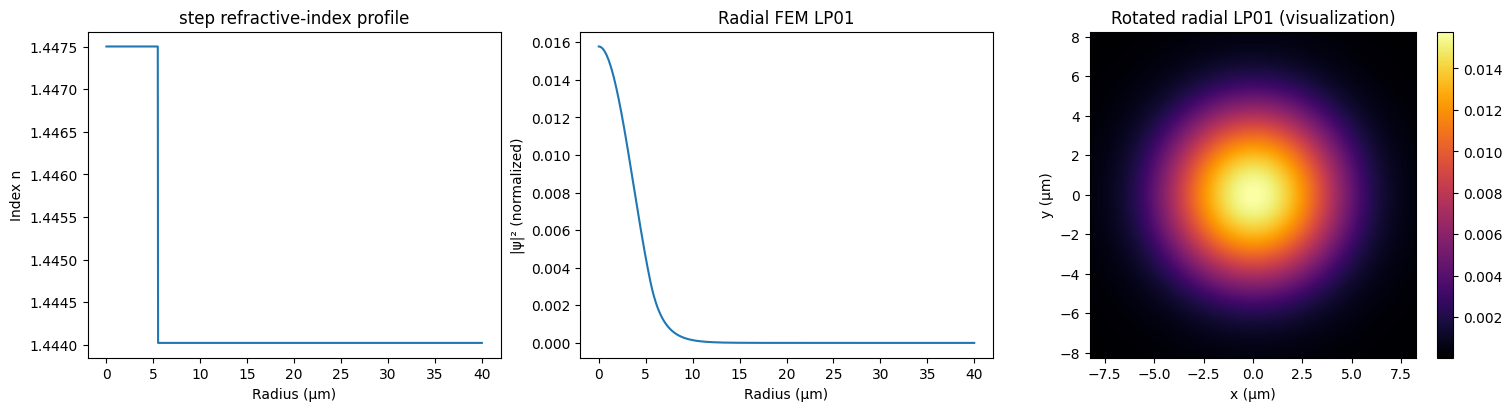

In [4]:
# 단면 굴절률과 FEM 방사형 모드 + 이를 축대칭 회전해 표시한 2D 단면(2D FEM 별도 해석 아님)
r=np.linspace(0,model.outer_radius_um,1200)
fig,ax=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
ax[0].plot(r,index_r(model,r));ax[0].set(xlabel='Radius (µm)',ylabel='Index n',title=f'{model.profile} refractive-index profile')
ax[1].plot(sol['r_um'],sol['field']**2);ax[1].set(xlabel='Radius (µm)',ylabel='|ψ|² (normalized)',title='Radial FEM LP01')
xy=np.linspace(-1.5*model.core_radius_um,1.5*model.core_radius_um,200)
xx,yy=np.meshgrid(xy,xy);rad=np.sqrt(xx*xx+yy*yy)
I=np.interp(rad.ravel(),sol['r_um'],sol['field']**2).reshape(rad.shape)
im=ax[2].imshow(I,extent=[xy.min(),xy.max(),xy.min(),xy.max()],origin='lower',cmap='inferno')
ax[2].set(xlabel='x (µm)',ylabel='y (µm)',title='Rotated radial LP01 (visualization)');ax[2].set_aspect('equal');fig.colorbar(im,ax=ax[2])
plt.show()


## 4. 파장 스윕: neff·Aeff·MFD·색분산 D

각 파장에서 **새 FEM 고유값 문제**를 풀고, D는 5점 파장 미분으로 계산합니다. **색분산은 작은 neff 수치 오차에 민감**하므로 메시 크기와 파장차 `D_STEP_NM`을 반드시 바꾸어 재확인해야 합니다. `n_core = n_silica + constant Δn`이라는 재료 가정을 유지합니다.

,lambda_nm,neff,MFD_PII_um,MFD_2nd_um,Aeff_um2,D_ps_nm_km,gamma_Wkm
0,1310,1.448845,11.190359,11.367315,101.019205,2.803970,1.044545
1,1450,1.447040,11.927645,12.168776,112.462133,13.506350,0.847673
2,1530,1.445986,12.382279,12.683977,119.935360,18.625188,0.753293
3,1550,1.445719,12.500070,12.819972,121.924352,19.825640,0.731443
4,1580,1.445316,12.680008,13.029667,125.005033,21.577419,0.699871
5,1610,1.444909,12.863966,13.246441,128.207664,23.277241,0.669673
6,1625,1.444704,12.957495,13.357570,129.856670,24.109844,0.655066


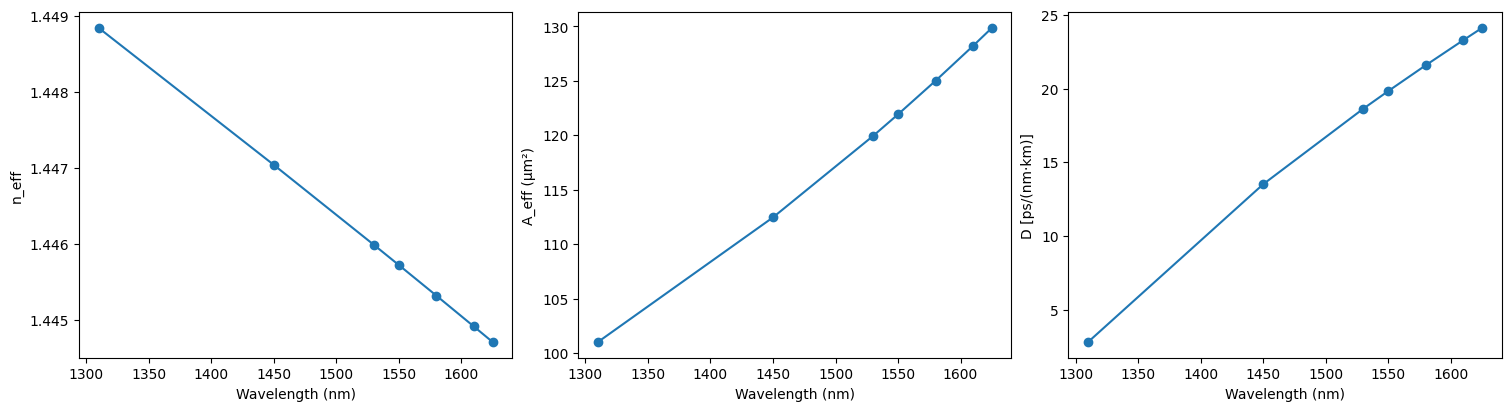

In [5]:
rows=[]
for wavelength in SWEEP_NM:
    x=replace(model,wavelength_nm=float(wavelength))
    s=solve_lp01(x,ELEMENTS)
    d=chromatic_dispersion(x,ELEMENTS,D_STEP_NM)
    rows.append({'lambda_nm':wavelength,'neff':s['neff'],'MFD_PII_um':s['MFD_PII_um'],
                 'MFD_2nd_um':s['MFD_2nd_um'],'Aeff_um2':s['Aeff_um2'],
                 'D_ps_nm_km':d,'gamma_Wkm':s['gamma_Wkm']})
sweep=pd.DataFrame(rows)
display(sweep.round(7))
fig,ax=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for axis,col,ylabel in zip(ax,['neff','Aeff_um2','D_ps_nm_km'],['n_eff','A_eff (µm²)','D [ps/(nm·km)]']):
    axis.plot(sweep.lambda_nm,sweep[col],'o-');axis.set(xlabel='Wavelength (nm)',ylabel=ylabel)
plt.show()


## 5. 메시 수렴 + 독립 Bessel 검증(일반 Step-index인 경우)

아래 독립 해석식은 Step-index이고 단일모드 V<2.405 조건에서만 사용합니다. **임의 Graded/Trench/Multilayer 모델에는 독립 해석식을 적용하지 않습니다.** 해당 구조의 검증은 메시·영역·미분간격 수렴 및 외부 기준값 확보가 별도로 필요합니다.

,elements,neff,Aeff_um2,MFD_PII_um,abs_neff_err_vs_Bessel,residual
0,160,1.445718,121.952910,12.501162,4.964980e-07,4.430485e-16
1,320,1.445719,121.930131,12.500291,1.242498e-07,1.723668e-15
2,640,1.445719,121.924415,12.500072,3.107442e-08,6.763493e-15
3,960,1.445719,121.923355,12.500032,1.381422e-08,1.553858e-14


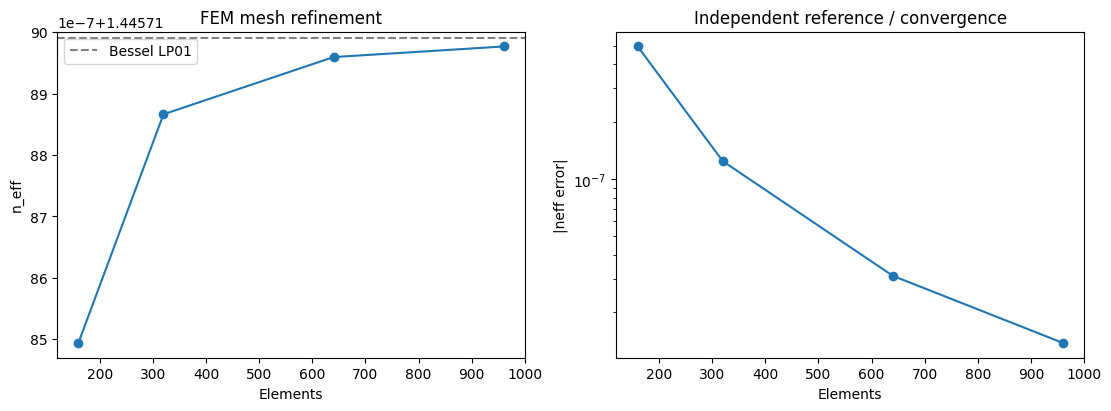

In [6]:
oracle=None
if model.profile=='step':
    try: oracle=bessel_step_oracle(model)
    except ValueError as ex: print('Bessel 기준 생략:',ex)
mesh_rows=[]
for N in (160,320,640,960):
    s=solve_lp01(model,N)
    mesh_rows.append({'elements':N,'neff':s['neff'],'Aeff_um2':s['Aeff_um2'],
                      'MFD_PII_um':s['MFD_PII_um'],
                      'abs_neff_err_vs_Bessel':abs(s['neff']-oracle['neff']) if oracle else np.nan,
                      'residual':s['residual']})
mesh=pd.DataFrame(mesh_rows)
display(mesh)
fig,ax=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
ax[0].plot(mesh.elements,mesh.neff,'o-');ax[0].set(xlabel='Elements',ylabel='n_eff',title='FEM mesh refinement')
if oracle:ax[0].axhline(oracle['neff'],ls='--',color='gray',label='Bessel LP01');ax[0].legend()
if oracle:ax[1].semilogy(mesh.elements,mesh.abs_neff_err_vs_Bessel,'o-')
else:ax[1].plot(mesh.elements,mesh.Aeff_um2,'o-')
ax[1].set(xlabel='Elements',ylabel='|neff error|' if oracle else 'Aeff (µm²)',title='Independent reference / convergence')
plt.show()


## 6. 간편 단면 비교 — 4가지 실리카 구조

**모두 예시 모델입니다.** 서로 다른 제조사 제품의 공식 실측값과 동일하다고 주장하지 않습니다.

In [7]:
comparison=[]
for name,settings in PRESETS.items():
    mm=Model(**settings)
    ss=solve_lp01(mm,500)
    comparison.append({'model':name,'neff':ss['neff'],'MFD_PII_um':ss['MFD_PII_um'],'Aeff_um2':ss['Aeff_um2'],
                       'D1550_ps_nm_km':chromatic_dispersion(mm,500)})
comp=pd.DataFrame(comparison)
display(comp.round(5))


,model,neff,MFD_PII_um,Aeff_um2,D1550_ps_nm_km
0,G.654.E-like (illustrative),1.44572,12.50012,121.92564,19.82558
1,G.652.D-like (illustrative),1.44610,10.18291,79.29586,16.99274
2,Graded core (illustrative),1.44583,10.19305,76.88761,14.91916
3,Trench-assisted (illustrative),1.44604,9.83941,74.82661,17.80367
4,Multilayer (illustrative),1.44700,9.58252,71.69077,19.16239


## 7. 자동 검사, 유효 범위와 보고서 저장

- **수치 통과는 제조사 규격 인증이 아닙니다.**
- 실제 실리카 도핑의 파장 의존 굴절률, Rayleigh 산란, PMD, microbend/bend, MCF/ARF는 이 버전에서 검증하지 않습니다.
- `D` 미분 간격 차이와 `outer_radius_um` 변경 결과도 보조 검증으로 출력합니다.
- 마지막 셀은 이 실행의 CSV/JSON/PNG를 ZIP으로 저장합니다.

In [8]:
D_hi=chromatic_dispersion(model,ELEMENTS,10.0)
D_lo=chromatic_dispersion(model,ELEMENTS,5.0)
large=solve_lp01(replace(model,outer_radius_um=model.outer_radius_um+10),ELEMENTS+150)
checks={
 'guided_proxy':bool(sol['guided_proxy']),
 'eigen_residual_lt_1e_8':bool(sol['residual']<1e-8),
 'outer_tail_fraction_lt_1e_4':bool(sol['tail_power']<1e-4),
 'mesh_neff_last_step_lt_5e_6':bool(abs(mesh.neff.iloc[-1]-mesh.neff.iloc[-2])<5e-6),
 'dispersion_step_diff_lt_0p5':bool(abs(D_hi-D_lo)<.5),
 'outer_domain_neff_diff_lt_5e_6':bool(abs(large['neff']-sol['neff'])<5e-6),
}
if oracle:checks['step_index_oracle_abs_neff_lt_1e_6']=bool(abs(sol['neff']-oracle['neff'])<1e-6)
display(pd.DataFrame([{'check':k,'pass':v} for k,v in checks.items()]))
print(f'기본 검증 {sum(checks.values())}/{len(checks)} PASS | D(10 nm)={D_hi:.5f}, D(5 nm)={D_lo:.5f} ps/(nm km)')


,check,pass
0,guided_proxy,True
1,eigen_residual_lt_1e_8,True
2,outer_tail_fraction_lt_1e_4,True
3,mesh_neff_last_step_lt_5e_6,True
4,dispersion_step_diff_lt_0p5,True
5,outer_domain_neff_diff_lt_5e_6,True
6,step_index_oracle_abs_neff_lt_1e_6,True


기본 검증 7/7 PASS | D(10 nm)=19.82564, D(5 nm)=19.82564 ps/(nm km)


In [9]:
from pathlib import Path
import zipfile,json,io
out=Path('Universal_Silica_Fiber_Output');out.mkdir(exist_ok=True)
summary.to_csv(out/'summary.csv',index=False);sweep.to_csv(out/'wavelength_sweep.csv',index=False)
mesh.to_csv(out/'mesh_convergence.csv',index=False);comp.to_csv(out/'fiber_comparison.csv',index=False)
record={'model':asdict(model),'solver':'axisymmetric weak-guidance scalar radial P1 FEM',
        'summary':serialize(sol),'checks':checks,'D_10nm':D_hi,'D_5nm':D_lo,
        'scope_warning':'Not full-vector, not actual manufacturer optical profile, not attenuation/cutoff/loss validation.'}
(out/'summary.json').write_text(json.dumps(record,ensure_ascii=False,indent=2))
# Plot files are saved anew from the computed tables and field, not stale stored results.
fig,ax=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
ax[0].plot(r,index_r(model,r));ax[0].set(xlabel='Radius (µm)',ylabel='n(r)',title='Input cross-section')
ax[1].plot(sol['r_um'],sol['field']**2);ax[1].set(xlabel='Radius (µm)',ylabel='LP01 intensity',title='Computed scalar FEM mode')
fig.savefig(out/'profile_and_mode.png',dpi=150);plt.close(fig)
fig,ax=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
ax[0].plot(sweep.lambda_nm,sweep.D_ps_nm_km,'o-');ax[0].set(xlabel='Wavelength (nm)',ylabel='D [ps/(nm km)]')
ax[1].plot(mesh.elements,mesh.neff,'o-');ax[1].set(xlabel='Radial FEM elements',ylabel='neff')
fig.savefig(out/'dispersion_and_convergence.png',dpi=150);plt.close(fig)
with zipfile.ZipFile('Universal_Silica_Fiber_Output.zip','w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in out.iterdir():z.write(p,p.name)
print('완료: Universal_Silica_Fiber_Output.zip')
# 필요하면 Colab 파일 패널에서 ZIP 다운로드


완료: Universal_Silica_Fiber_Output.zip
